# Real-Time Air Quality Forecasting and Spike Detection for Karachi
**Team:** Naresh Kumar (25K-2501) and Syed Zaid Khalid (25K-2522)

Run the cells from top to bottom.

| Part | Phases | What it does |
|---|---|---|
| 1 | 2 and 3 | Data quality report, cleaning, features, and exploration (EDA) |
| 2 | 4 and 5 | SARIMA forecasting (with residual and confidence-band checks) and spike detection |
| 3 | 6 | Baseline models, comparison, and a significance test |
| 4 | extra | Checks against real-world data (ground sensors, Open-Meteo's own forecast) |
| 5 | extra | Ways to improve accuracy (health-category accuracy, predicting the change, extra columns, averaging models) |

**Before you start:** run `backfill.py` once to create `karachi_aq_history.csv` (and `refresh.py` any time you want newer data).
This notebook creates: `data_quality_report.csv`, `clean_data.csv`, `sarima_results.csv`, `band_coverage.csv`, `spike_flags.csv`,
`model_comparison.csv`, `significance_results.csv`, `sensitivity_results.csv`, `model.pkl`.

The full run takes a few minutes, mostly in the SARIMA steps.

## Settings (used in several parts)

In [1]:
import numpy as np

# forecast from a new starting point every 3 hours.
# More starting points = more reliable error numbers. Parts 2 and 3 both use this number.
origin_step = 3

# when SARIMA makes a forecast it looks at the last 14 days of history (this keeps it fast)
history_window = 24 * 14

# fixed random seed, so the results are the same every time you run it
np.random.seed(42)

# Part 1: Phases 2 and 3 - Cleaning, features and exploration
Uses `karachi_aq_history.csv` made by `backfill.py`.


## Phase 2: Cleaning and features

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 1: Load the data and check it

In [3]:
table = pd.read_csv("karachi_aq_history.csv")

print("Rows and columns:", table.shape)
print(table.head())
print(table.info())

Rows and columns: (17531, 8)
                  time  pm2_5  pm10  nitrogen_dioxide  ozone  temperature_2m  \
0  2024-11-16 00:00:00   39.3  41.9              33.6   64.0            24.9   
1  2024-11-16 01:00:00   38.4  41.1              27.5   67.0            24.6   
2  2024-11-16 02:00:00   37.1  39.9              22.3   69.0            24.4   
3  2024-11-16 03:00:00   35.6  38.5              17.1   72.0            24.2   
4  2024-11-16 04:00:00   34.0  37.1              12.9   74.0            23.8   

   relative_humidity_2m  wind_speed_10m  
0                    68             7.9  
1                    72             9.2  
2                    76             8.7  
3                    79             7.2  
4                    82             6.1  
<class 'pandas.DataFrame'>
RangeIndex: 17531 entries, 0 to 17530
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  17531 non-nu

### Data quality report
A quick check for common data problems before we clean anything. The numbers are saved in `data_quality_report.csv`.

In [4]:
# 1. missing values
missing_total = table.isna().sum().sum()

# 2. duplicate timestamps
duplicate_times = table["time"].duplicated().sum()

# 3. gaps in time (a step that is not exactly 1 hour)
sorted_times = pd.to_datetime(table["time"]).drop_duplicates().sort_values()
steps = sorted_times.diff().dropna()
gap_count = (steps != pd.Timedelta(hours=1)).sum()

# 4. outliers in PM2.5 (above Q3 + 1.5 x IQR) and impossible values (below 0)
pm_values = table["pm2_5"].dropna()
q1 = pm_values.quantile(0.25)
q3 = pm_values.quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
outlier_count = (pm_values > upper_limit).sum()
negative_count = (pm_values < 0).sum()

# 5. flat stretches (the same PM2.5 value 6 hours in a row can mean a stuck sensor or model)
same_as_before = (pm_values == pm_values.shift(1))
flat_count = same_as_before.rolling(5).sum().ge(5).sum()

report_rows = [
    {"check": "Rows", "result": len(table)},
    {"check": "First hour", "result": str(sorted_times.min())},
    {"check": "Last hour", "result": str(sorted_times.max())},
    {"check": "Missing values (all columns)", "result": int(missing_total)},
    {"check": "Duplicate timestamps", "result": int(duplicate_times)},
    {"check": "Time gaps (not exactly 1 hour)", "result": int(gap_count)},
    {"check": "PM2.5 outliers (above " + str(round(upper_limit, 1)) + ")", "result": int(outlier_count)},
    {"check": "PM2.5 below zero", "result": int(negative_count)},
    {"check": "Flat stretches (6 equal values in a row)", "result": int(flat_count)},
]

report = pd.DataFrame(report_rows)
print(report)
report.to_csv("data_quality_report.csv", index=False)

                                      check               result
0                                      Rows                17531
1                                First hour  2024-11-16 00:00:00
2                                 Last hour  2026-11-16 10:00:00
3              Missing values (all columns)                    0
4                      Duplicate timestamps                    0
5            Time gaps (not exactly 1 hour)                    0
6               PM2.5 outliers (above 54.8)                  824
7                          PM2.5 below zero                    0
8  Flat stretches (6 equal values in a row)                    0


**Interpretation:** (which problems did we find? the next steps remove duplicates and fill gaps; outliers are kept because real pollution spikes are the thing we want to study.)

### Step 2: Fix the time column and remove duplicates

In [5]:
# make the time column a real date and time
table["time"] = pd.to_datetime(table["time"])

# put rows in time order
table = table.sort_values("time")

# remove rows that have the same time twice
rows_before = len(table)
table = table.drop_duplicates(subset="time")
rows_after = len(table)

print("Duplicate rows removed:", rows_before - rows_after)

Duplicate rows removed: 0


### Step 3: Fill missing values

In [6]:
# how many missing values in each column
print(table.isna().sum())

time                    0
pm2_5                   0
pm10                    0
nitrogen_dioxide        0
ozone                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [7]:
# fill small gaps using the values before and after
table = table.set_index("time")
table = table.interpolate(method="time")
table = table.reset_index()

# check again, it should now be 0 (or very small)
print(table.isna().sum())

time                    0
pm2_5                   0
pm10                    0
nitrogen_dioxide        0
ozone                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


### Step 4: Add time columns

In [8]:
table["hour"] = table["time"].dt.hour
table["day_of_week"] = table["time"].dt.dayofweek    # 0 = Monday, 6 = Sunday
table["month"] = table["time"].dt.month

# weekend = Saturday or Sunday
table["is_weekend"] = 0
table.loc[table["day_of_week"] >= 5, "is_weekend"] = 1

# night = 10 PM to 5 AM
table["is_night"] = 0
table.loc[(table["hour"] >= 22) | (table["hour"] <= 5), "is_night"] = 1

# rush hours = 7 to 10 AM and 5 to 8 PM
table["is_rush_hour"] = 0
table.loc[(table["hour"] >= 7) & (table["hour"] <= 10), "is_rush_hour"] = 1
table.loc[(table["hour"] >= 17) & (table["hour"] <= 20), "is_rush_hour"] = 1

print(table[["time", "hour", "day_of_week", "is_weekend", "is_night", "is_rush_hour"]].head())

                 time  hour  day_of_week  is_weekend  is_night  is_rush_hour
0 2024-11-16 00:00:00     0            5           1         1             0
1 2024-11-16 01:00:00     1            5           1         1             0
2 2024-11-16 02:00:00     2            5           1         1             0
3 2024-11-16 03:00:00     3            5           1         1             0
4 2024-11-16 04:00:00     4            5           1         1             0


### Step 5: Add past-value columns (lags) and rolling averages
Each row only uses values from the PAST, so the model never sees the future.

In [9]:
# PM2.5 value 1, 3 and 24 hours ago
table["pm2_5_lag1"] = table["pm2_5"].shift(1)
table["pm2_5_lag3"] = table["pm2_5"].shift(3)
table["pm2_5_lag24"] = table["pm2_5"].shift(24)

# average of the last 3 and last 24 hours (not including the current hour)
past_pm = table["pm2_5"].shift(1)
table["pm2_5_avg3"] = past_pm.rolling(3).mean()
table["pm2_5_avg24"] = past_pm.rolling(24).mean()

# the first 24 rows have no past values, so remove them
table = table.dropna()

print("Rows and columns after cleaning:", table.shape)
print(table.head())

Rows and columns after cleaning: (17507, 19)
                  time  pm2_5  pm10  nitrogen_dioxide  ozone  temperature_2m  \
24 2024-11-17 00:00:00   31.8  37.6              53.3   28.0            25.2   
25 2024-11-17 01:00:00   31.7  38.2              47.0   32.0            24.7   
26 2024-11-17 02:00:00   30.6  37.4              40.7   36.0            24.0   
27 2024-11-17 03:00:00   29.1  36.0              33.9   40.0            23.5   
28 2024-11-17 04:00:00   26.8  33.2              27.1   43.0            23.0   

    relative_humidity_2m  wind_speed_10m  hour  day_of_week  month  \
24                    80             5.7     0            6     11   
25                    83             4.1     1            6     11   
26                    85             7.1     2            6     11   
27                    87             5.7     3            6     11   
28                    90             6.2     4            6     11   

    is_weekend  is_night  is_rush_hour  pm2_5_lag1  p

### Step 6: Save the clean table

In [10]:
table.to_csv("clean_data.csv", index=False)
print("Saved clean_data.csv")

Saved clean_data.csv


## Phase 3: Exploration (EDA)

### Summary numbers

In [11]:
print(table[["pm2_5", "pm10", "nitrogen_dioxide", "ozone", "temperature_2m", "relative_humidity_2m", "wind_speed_10m"]].describe())

              pm2_5          pm10  nitrogen_dioxide         ozone  \
count  17507.000000  17507.000000      17507.000000  17507.000000   
mean      28.641303     54.609014         20.483669     70.841321   
std       12.735030     31.772402         18.923995     39.443493   
min        3.500000      3.700000          0.000000      0.000000   
25%       20.000000     34.800000          7.300000     43.000000   
50%       25.600000     48.000000         13.500000     62.000000   
75%       33.900000     65.700000         27.300000     94.000000   
max      108.700000    504.800000        138.500000    213.000000   

       temperature_2m  relative_humidity_2m  wind_speed_10m  
count    17507.000000          17507.000000    17507.000000  
mean        26.601965             64.377106       10.826378  
std          4.673315             21.351763        4.404703  
min          9.300000              5.000000        0.200000  
25%         23.900000             50.000000        7.600000  
50%   

### Chart 1: PM2.5 over time

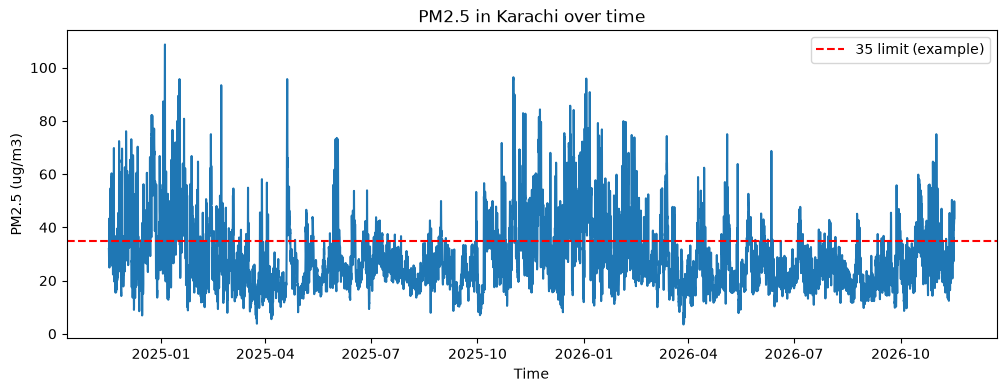

In [12]:
plt.figure(figsize=(12, 4))
plt.plot(table["time"], table["pm2_5"])
plt.axhline(35, color="red", linestyle="--", label="35 limit (example)")
plt.title("PM2.5 in Karachi over time")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (write 2 or 3 sentences after you see the chart: is there a trend? are there big spikes?)

### Chart 2: Average PM2.5 by hour of day

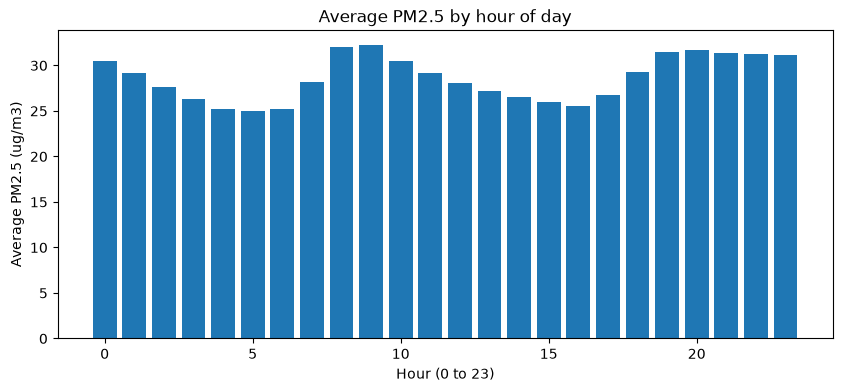

In [13]:
hour_average = table.groupby("hour")["pm2_5"].mean()

plt.figure(figsize=(10, 4))
plt.bar(hour_average.index, hour_average.values)
plt.title("Average PM2.5 by hour of day")
plt.xlabel("Hour (0 to 23)")
plt.ylabel("Average PM2.5 (ug/m3)")
plt.show()

**Interpretation:** (which hours are highest and lowest? does it match rush hours?)

### Chart 3: Average PM2.5 by day of week

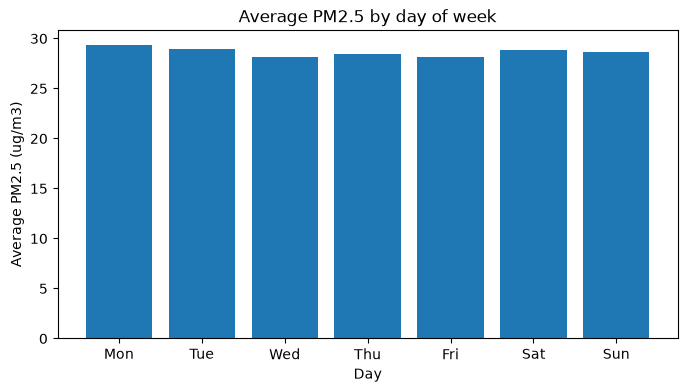

In [14]:
day_average = table.groupby("day_of_week")["pm2_5"].mean()
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(8, 4))
plt.bar(day_names, day_average.values)
plt.title("Average PM2.5 by day of week")
plt.xlabel("Day")
plt.ylabel("Average PM2.5 (ug/m3)")
plt.show()

**Interpretation:** (is the weekend different from weekdays?)

### Chart 4: PM2.5 versus wind speed and humidity

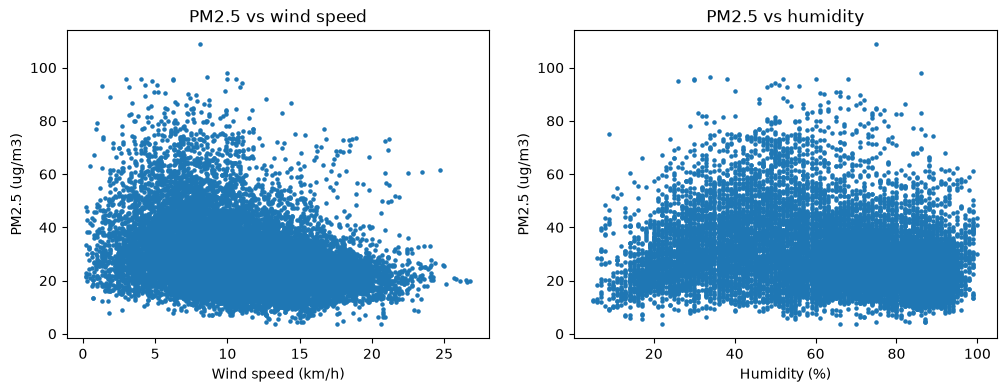

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(table["wind_speed_10m"], table["pm2_5"], s=5)
plt.title("PM2.5 vs wind speed")
plt.xlabel("Wind speed (km/h)")
plt.ylabel("PM2.5 (ug/m3)")

plt.subplot(1, 2, 2)
plt.scatter(table["relative_humidity_2m"], table["pm2_5"], s=5)
plt.title("PM2.5 vs humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("PM2.5 (ug/m3)")

plt.show()

**Interpretation:** (does more wind mean less PM2.5? what about humidity?)

### Chart 5: Correlation heatmap

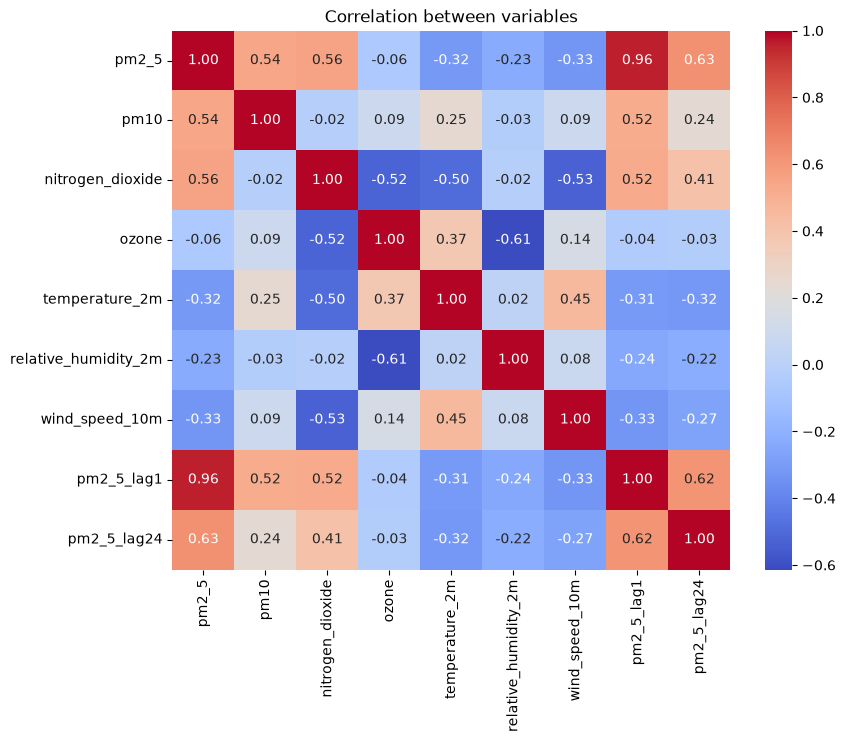

In [16]:
small_table = table[["pm2_5", "pm10", "nitrogen_dioxide", "ozone", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "pm2_5_lag1", "pm2_5_lag24"]]

plt.figure(figsize=(9, 7))
sns.heatmap(small_table.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between variables")
plt.show()

**Interpretation:** (which variables are most related to PM2.5? is lag1 very high? what does that mean for forecasting?)

## Notes for the report
- Data comes from the CAMS model through Open-Meteo, not from ground sensors.
- The 35 line on the charts is an example limit. Confirm the exact standard you cite.
- Next: Phase 4 (SARIMA) will use `clean_data.csv`.

# Part 2: Phases 4 and 5 - SARIMA forecasting and spike detection
Uses `clean_data.csv` made in Part 1.
Install once if needed: `pip install statsmodels scikit-learn`


## Phase 4: SARIMA forecasting

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

### Step 1: Load the clean data and split it by time

In [18]:
table = pd.read_csv("clean_data.csv")
table["time"] = pd.to_datetime(table["time"])

# only the PM2.5 numbers, in time order
pm = table["pm2_5"].reset_index(drop=True)

# first 80% of hours = training, last 20% = testing (no shuffling!)
test_start = int(len(pm) * 0.8)
train = pm[:test_start]
test = pm[test_start:]

print("Training hours:", len(train))
print("Testing hours:", len(test))

Training hours: 14005
Testing hours: 3502


### Step 2: Fit the SARIMA model
`order=(1,0,1)` means: use the last hour (AR) and the last error (MA).
`seasonal_order=(1,0,1,24)` means: the same idea, but for the 24-hour daily cycle.
This step can take about a minute.

In [19]:
# fit on the last 90 days before the test period (the daily cycle is learned quickly, and this keeps it fast)
fit_data = train[-24 * 90:]

model = SARIMAX(fit_data, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24))
results = model.fit(disp=False)

print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              pm2_5   No. Observations:                 2160
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 24)   Log Likelihood               -4643.462
Date:                            Mon, 16 Nov 2026   AIC                           9296.925
Time:                                    10:49:54   BIC                           9325.314
Sample:                                         0   HQIC                          9307.308
                                           - 2160                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9515      0.004    226.163      0.000       0.943       0.960
ma.L1          0.4175      0.010   

### Step 2b: Residual check
Residuals = real PM2.5 minus what the fitted model expected. If the model captured the daily pattern,
the residuals should look like random noise with no repeating pattern left.

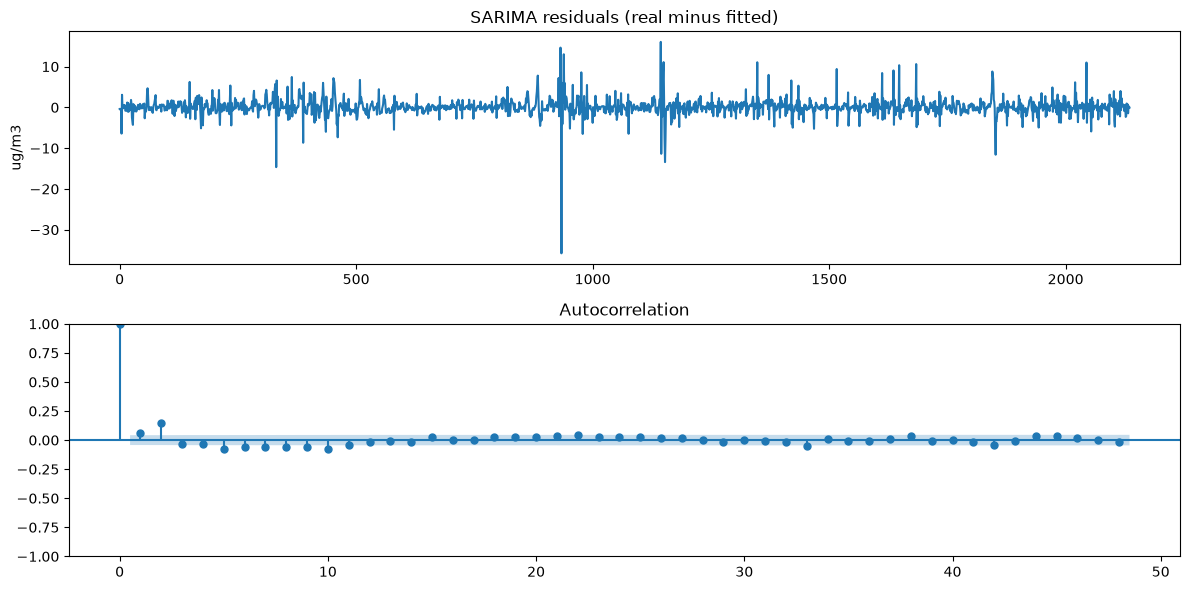

       lb_stat     lb_pvalue
24  135.711651  1.419996e-17


In [20]:
residuals = results.resid[24:]       # skip the first day (the model is still warming up)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(residuals.values)
plt.title("SARIMA residuals (real minus fitted)")
plt.ylabel("ug/m3")

plt.subplot(2, 1, 2)
plot_acf(residuals, lags=48, ax=plt.gca())

plt.tight_layout()
plt.show()

# Ljung-Box test: a small p-value (below 0.05) means some pattern is still left in the residuals
ljung = acorr_ljungbox(residuals, lags=[24])
print(ljung)

**Interpretation:** (do the bars in the lower chart stay mostly inside the blue band? is the Ljung-Box p-value above 0.05?
Some leftover pattern is common with simple models. If you see it, say so honestly in the report.)

### Step 3: Forecast the next 72 hours and draw it with the confidence band

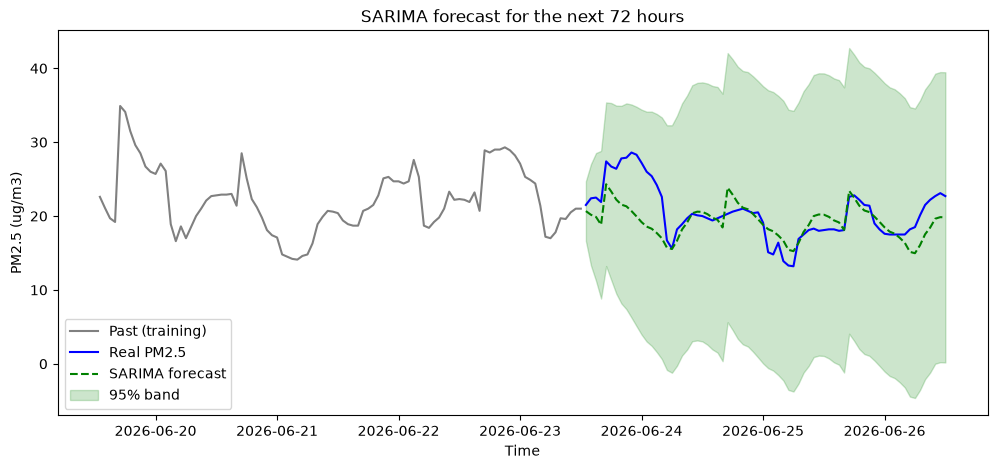

In [21]:
forecast = results.get_forecast(steps=72)
forecast_values = forecast.predicted_mean
band = forecast.conf_int()
lower = band.iloc[:, 0]
upper = band.iloc[:, 1]

# real values for the same 72 hours
real_values = test[:72]

# time labels for the chart
past_times = table["time"][test_start - 96 : test_start]
future_times = table["time"][test_start : test_start + 72]
past_values = train[test_start - 96 : test_start]

plt.figure(figsize=(12, 5))
plt.plot(past_times, past_values, color="gray", label="Past (training)")
plt.plot(future_times, real_values.values, color="blue", label="Real PM2.5")
plt.plot(future_times, forecast_values.values, color="green", linestyle="--", label="SARIMA forecast")
plt.fill_between(future_times, lower.values, upper.values, color="green", alpha=0.2, label="95% band")
plt.title("SARIMA forecast for the next 72 hours")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (does the forecast follow the daily up and down? does the band get wider further away?)

### Step 4: Measure the error at +1, +6, +24, +48 and +72 hours
We repeat the forecast from many starting points in the test period (every `origin_step` hours, set at the top of the notebook),
so each horizon gets several errors, not just one.
We also test the naive baseline: the value at the same hour on the last known day.

In [22]:
horizons = [1, 6, 24, 48, 72]

# empty lists to collect errors
sarima_errors = {}
naive_errors = {}
band_hits = {}
backtest_list = []      # the +24 hour predictions, kept for the dashboard and a chart
for h in horizons:
    sarima_errors[h] = []
    naive_errors[h] = []
    band_hits[h] = []

origin = test_start
while origin + 72 <= len(pm):

    # everything we know up to this moment
    # the last 14 days we know up to this moment
    history = pm[max(0, origin - history_window) : origin]

    # reuse the learned model on the new history (no refit, so it is fast)
    new_results = results.apply(history, refit=False)
    new_forecast_all = new_results.get_forecast(steps=72)
    new_forecast = new_forecast_all.predicted_mean
    new_band = new_forecast_all.conf_int()

    for h in horizons:
        target_position = origin + h - 1
        real = pm[target_position]

        # SARIMA error
        sarima_guess = new_forecast.iloc[h - 1]
        sarima_errors[h].append(real - sarima_guess)

        # was the real value inside the 95% band?
        band_low = new_band.iloc[h - 1, 0]
        band_high = new_band.iloc[h - 1, 1]
        if band_low <= real <= band_high:
            band_hits[h].append(1)
        else:
            band_hits[h].append(0)

        # naive guess: same hour, on the last day we already know
        days_back = (h + 23) // 24
        naive_guess = pm[target_position - 24 * days_back]
        naive_errors[h].append(real - naive_guess)

        # keep the +24 hour predictions (time = the hour that was predicted)
        if h == 24:
            backtest_list.append({
                "time": table["time"][target_position],
                "real": real,
                "sarima_24h": sarima_guess,
                "naive_24h": naive_guess,
            })

    # move the starting point forward by 24 hours
    origin = origin + origin_step

print("Number of starting points used:", len(sarima_errors[1]))

Number of starting points used: 1144


In [23]:
rows = []
for h in horizons:
    s_errors = np.array(sarima_errors[h])
    n_errors = np.array(naive_errors[h])

    row = {
        "horizon_hours": h,
        "SARIMA_RMSE": np.sqrt(np.mean(s_errors ** 2)),
        "SARIMA_MAE": np.mean(np.abs(s_errors)),
        "Naive_RMSE": np.sqrt(np.mean(n_errors ** 2)),
        "Naive_MAE": np.mean(np.abs(n_errors)),
    }
    rows.append(row)

results_table = pd.DataFrame(rows)
results_table = results_table.round(2)
print(results_table)

results_table.to_csv("sarima_results.csv", index=False)

   horizon_hours  SARIMA_RMSE  SARIMA_MAE  Naive_RMSE  Naive_MAE
0              1         1.76        1.09        6.49       4.71
1              6         5.68        3.89        6.44       4.70
2             24         6.67        4.73        6.46       4.74
3             48         8.15        5.74        8.00       5.95
4             72         9.01        6.42        9.19       6.84


### Step 4b: Is the 95% band honest?
A good 95% band should contain the real value about 95% of the time. Much lower means the model is overconfident.

   horizon_hours  percent_inside_95_band
0              1                    96.1
1              6                    94.7
2             24                    97.5
3             48                    96.3
4             72                    95.7


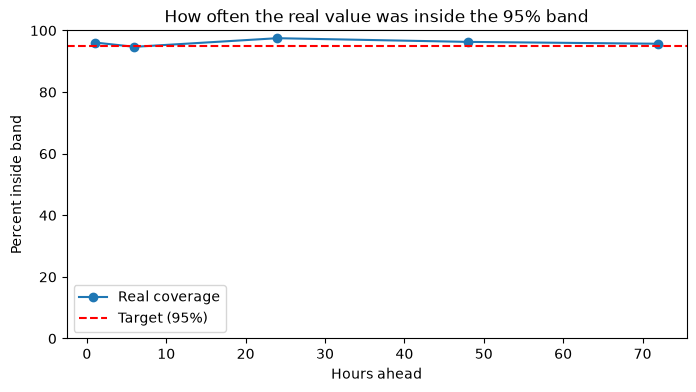

In [24]:
coverage_rows = []
for h in horizons:
    hits = np.array(band_hits[h])
    coverage_rows.append({"horizon_hours": h, "percent_inside_95_band": round(hits.mean() * 100, 1)})

coverage_table = pd.DataFrame(coverage_rows)
print(coverage_table)
coverage_table.to_csv("band_coverage.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(coverage_table["horizon_hours"], coverage_table["percent_inside_95_band"], marker="o", label="Real coverage")
plt.axhline(95, color="red", linestyle="--", label="Target (95%)")
plt.title("How often the real value was inside the 95% band")
plt.xlabel("Hours ahead")
plt.ylabel("Percent inside band")
plt.ylim(0, 100)
plt.legend()
plt.show()

**Interpretation:** (is coverage close to 95%? at which horizon does the band become too narrow or too wide?)

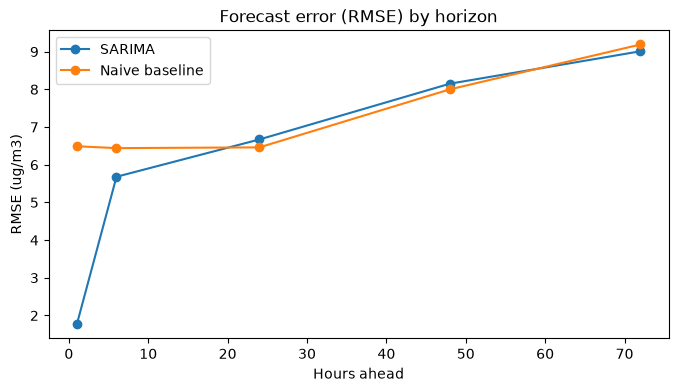

In [25]:
plt.figure(figsize=(8, 4))
plt.plot(results_table["horizon_hours"], results_table["SARIMA_RMSE"], marker="o", label="SARIMA")
plt.plot(results_table["horizon_hours"], results_table["Naive_RMSE"], marker="o", label="Naive baseline")
plt.title("Forecast error (RMSE) by horizon")
plt.xlabel("Hours ahead")
plt.ylabel("RMSE (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (does the error grow with the horizon? does SARIMA beat the naive baseline at every horizon?
Remember: each horizon uses only a few starting points, so say the results are approximate.)

## Phase 5: Spike detection

In [26]:
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

### Step 1: Prepare the columns
We add one helpful column: how far PM2.5 is from its normal level at that hour of the day.
The normal level is learned from the training hours only.

In [27]:
train_table = table[:test_start]
test_table = table[test_start:]

# normal PM2.5 for each hour of day (from training hours only)
hour_normal = train_table.groupby("hour")["pm2_5"].mean()
table["hour_average"] = table["hour"].map(hour_normal)
table["pm_vs_hour"] = table["pm2_5"] - table["hour_average"]

# the columns the detectors will look at
features = ["pm2_5", "pm10", "wind_speed_10m", "relative_humidity_2m", "pm_vs_hour"]

train_table = table[:test_start]
test_table = table[test_start:]

### Step 2: Isolation Forest
It learns from the training hours, then judges every hour.
`contamination=0.02` means we expect about 2% of hours to be unusual.

In [28]:
iso_model = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
iso_model.fit(train_table[features])

answer = iso_model.predict(table[features])      # -1 = unusual, 1 = normal

table["if_spike"] = 0
table.loc[answer == -1, "if_spike"] = 1

test_table = table[test_start:]
print("Hours flagged by Isolation Forest in the test period:", test_table["if_spike"].sum(), "out of", len(test_table))

Hours flagged by Isolation Forest in the test period: 4 out of 3502


### Step 3: A simple rule to compare with (PM2.5 above the 95th percentile of training)

In [29]:
limit = train_table["pm2_5"].quantile(0.95)
print("Rule limit (ug/m3):", round(limit, 1))

table["rule_spike"] = 0
table.loc[table["pm2_5"] > limit, "rule_spike"] = 1

test_table = table[test_start:]

both = len(test_table[(test_table["if_spike"] == 1) & (test_table["rule_spike"] == 1)])
only_if = len(test_table[(test_table["if_spike"] == 1) & (test_table["rule_spike"] == 0)])
only_rule = len(test_table[(test_table["if_spike"] == 0) & (test_table["rule_spike"] == 1)])

print("Flagged by both:", both)
print("Flagged only by Isolation Forest:", only_if)
print("Flagged only by the simple rule:", only_rule)

Rule limit (ug/m3): 56.3
Flagged by both: 1
Flagged only by Isolation Forest: 3
Flagged only by the simple rule: 26


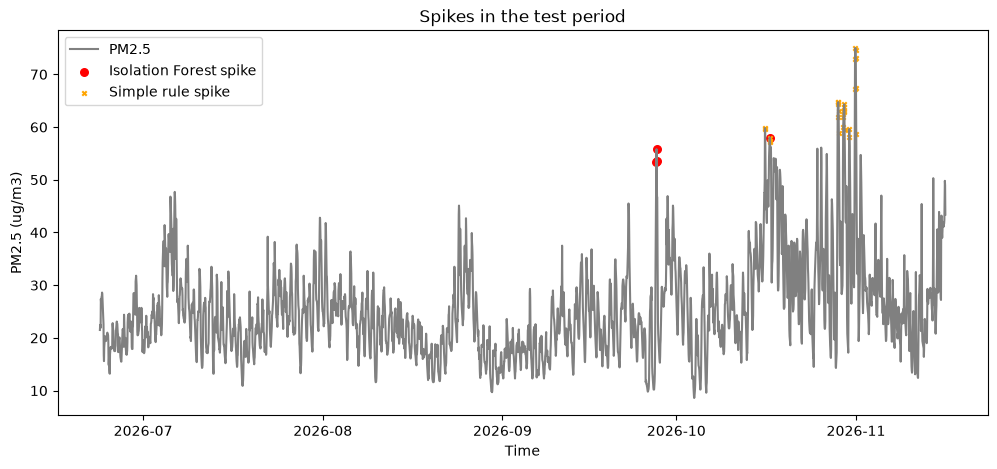

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(test_table["time"], test_table["pm2_5"], color="gray", label="PM2.5")

if_points = test_table[test_table["if_spike"] == 1]
plt.scatter(if_points["time"], if_points["pm2_5"], color="red", s=30, label="Isolation Forest spike")

rule_points = test_table[test_table["rule_spike"] == 1]
plt.scatter(rule_points["time"], rule_points["pm2_5"], color="orange", s=10, marker="x", label="Simple rule spike")

plt.title("Spikes in the test period")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (which spikes did only Isolation Forest find? are they unusual for that hour even if not very high?
which ones did only the rule find?)

### Step 4 (optional): DBSCAN, a second opinion
First we scale the columns so they have the same size. Then DBSCAN marks hours that are far from the crowd as noise (label -1).
`eps` controls how far counts as "close". Try different values and pick one that flags a small share of hours.

In [31]:
scaler = StandardScaler()
scaler.fit(train_table[features])
scaled_all = scaler.transform(table[features])

# try a few eps values
for eps_value in [0.5, 1.0, 1.5, 2.0, 2.5]:
    labels = DBSCAN(eps=eps_value, min_samples=10).fit_predict(scaled_all)
    noise_count = (labels == -1).sum()
    print("eps =", eps_value, "-> hours marked unusual:", noise_count, "out of", len(labels))

eps = 0.5 -> hours marked unusual: 890 out of 17507


eps = 1.0 -> hours marked unusual: 92 out of 17507


eps = 1.5 -> hours marked unusual: 8 out of 17507


eps = 2.0 -> hours marked unusual: 2 out of 17507


eps = 2.5 -> hours marked unusual: 2 out of 17507


In [32]:
# choose your eps from the list above
chosen_eps = 1.5

labels = DBSCAN(eps=chosen_eps, min_samples=10).fit_predict(scaled_all)

table["db_spike"] = 0
table.loc[labels == -1, "db_spike"] = 1

test_table = table[test_start:]

both = len(test_table[(test_table["if_spike"] == 1) & (test_table["db_spike"] == 1)])
only_if = len(test_table[(test_table["if_spike"] == 1) & (test_table["db_spike"] == 0)])
only_db = len(test_table[(test_table["if_spike"] == 0) & (test_table["db_spike"] == 1)])

print("Flagged by both Isolation Forest and DBSCAN:", both)
print("Flagged only by Isolation Forest:", only_if)
print("Flagged only by DBSCAN:", only_db)

Flagged by both Isolation Forest and DBSCAN: 0
Flagged only by Isolation Forest: 4
Flagged only by DBSCAN: 0


**Interpretation:** (do the two methods agree? hours both flag are the most trustworthy spikes.)

### Save the flags

In [33]:
table[["time", "pm2_5", "if_spike", "rule_spike", "db_spike"]].to_csv("spike_flags.csv", index=False)
print("Saved spike_flags.csv")

Saved spike_flags.csv


## Notes for the report
- SARIMA was fitted once on the training hours and re-used (without refitting) from many starting points in the test period.
- There are no true "spike" labels, so spikes are compared against a simple rule and between methods, not scored for accuracy.
- Next: Phase 6 adds the baselines (Linear Regression, Random Forest, Gradient Boosting) once they are taught.

# Part 3: Phase 6 - Baseline models and comparison
Uses `clean_data.csv` (Part 1) and `sarima_results.csv` (Part 2).

**Course rule:** use Linear Regression and Random Forest only after they are taught, and Gradient Boosting only after weeks 11-12.
Set `use_gradient_boosting = False` below until your professor has taught it.


In [34]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

# change to False until Gradient Boosting is taught in class
use_gradient_boosting = True

## Step 1: Load the data and choose the columns

In [35]:
table = pd.read_csv("clean_data.csv")
table["time"] = pd.to_datetime(table["time"])

# same split as Phase 4: first 80% training, last 20% testing
test_start = int(len(table) * 0.8)

all_features = [
    "pm2_5", "pm10", "nitrogen_dioxide", "ozone",
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "hour", "day_of_week", "is_weekend", "is_night", "is_rush_hour",
    "pm2_5_lag1", "pm2_5_lag3", "pm2_5_lag24", "pm2_5_avg3", "pm2_5_avg24",
]

weather_features = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]

horizons = [1, 6, 24, 48, 72]
print("Rows:", len(table), " Test starts at row:", test_start)

Rows: 17507  Test starts at row: 14005


## Step 2: A helper that builds training and testing data for one horizon
For a horizon of h hours, each row says: "using what we know NOW, what will PM2.5 be h hours later?"
- Training rows: their target must still be inside the training period (no peeking at the test period).
- Test rows: the same starting points that SARIMA used (every `origin_step` hours, the same number as in Part 2), so the comparison is fair.

In [36]:
def make_data(h, feature_list, first_train_row=0):
    data = table.copy()

    # the hour of day we are trying to predict
    data["target_hour"] = (data["hour"] + h) % 24

    # the answer: PM2.5 h hours later
    data["target"] = data["pm2_5"].shift(-h)

    columns = feature_list + ["target_hour"]

    train_rows = list(range(first_train_row, test_start - h))
    test_rows = list(range(test_start - 1, len(table) - 72, origin_step))

    x_train = data.loc[train_rows, columns]
    y_train = data.loc[train_rows, "target"]
    x_test = data.loc[test_rows, columns]
    y_test = data.loc[test_rows, "target"]

    return x_train, y_train, x_test, y_test


def get_errors(real, guess):
    errors = np.array(real) - np.array(guess)
    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))
    return rmse, mae

## Step 3: Train the models for every horizon
Linear Regression works best when columns have a similar size, so we scale them for that model only.

In [37]:
rows = []
ml_errors = {}      # we keep every error so we can test the differences later

for h in horizons:
    x_train, y_train, x_test, y_test = make_data(h, all_features)

    # scaled copy for Linear Regression
    mean = x_train.mean()
    std = x_train.std().replace(0, 1)
    x_train_scaled = (x_train - mean) / std
    x_test_scaled = (x_test - mean) / std

    row = {"horizon_hours": h}

    # Linear Regression
    linear_model = LinearRegression()
    linear_model.fit(x_train_scaled, y_train)
    guess = linear_model.predict(x_test_scaled)
    ml_errors["LinearRegression_" + str(h)] = np.array(y_test) - np.array(guess)
    if h == 24:
        linear_24_guess = guess
        index_24 = x_test.index
    rmse, mae = get_errors(y_test, guess)
    row["LinearRegression_RMSE"] = rmse
    row["LinearRegression_MAE"] = mae

    # Random Forest
    forest_model = RandomForestRegressor(n_estimators=200, random_state=42)
    forest_model.fit(x_train, y_train)
    guess = forest_model.predict(x_test)
    ml_errors["RandomForest_" + str(h)] = np.array(y_test) - np.array(guess)
    if h == 24:
        forest_24_guess = guess
    rmse, mae = get_errors(y_test, guess)
    row["RandomForest_RMSE"] = rmse
    row["RandomForest_MAE"] = mae

    # Gradient Boosting (only after it is taught)
    if use_gradient_boosting:
        boost_model = GradientBoostingRegressor(random_state=42)
        boost_model.fit(x_train, y_train)
        guess = boost_model.predict(x_test)
        ml_errors["GradientBoosting_" + str(h)] = np.array(y_test) - np.array(guess)
        rmse, mae = get_errors(y_test, guess)
        row["GradientBoosting_RMSE"] = rmse
        row["GradientBoosting_MAE"] = mae

    rows.append(row)
    print("Done horizon", h)

ml_table = pd.DataFrame(rows)
print(ml_table.round(2))

Done horizon 1


Done horizon 6


Done horizon 24


Done horizon 48


Done horizon 72
   horizon_hours  LinearRegression_RMSE  LinearRegression_MAE  \
0              1                   1.91                  1.18   
1              6                   5.79                  4.25   
2             24                   6.21                  4.78   
3             48                   7.52                  5.79   
4             72                   8.14                  6.32   

   RandomForest_RMSE  RandomForest_MAE  GradientBoosting_RMSE  \
0               1.78              1.11                   1.90   
1               5.32              3.78                   5.38   
2               6.31              4.63                   6.17   
3               7.66              5.67                   7.36   
4               8.32              6.26                   7.94   

   GradientBoosting_MAE  
0                  1.23  
1                  3.90  
2                  4.66  
3                  5.50  
4                  5.99  


### Step 3b: Predicted vs actual (+24 hours) over the test period
Each point is a forecast that was made 24 hours earlier for that hour, using only what was known at that time.
This is the "what did the model predict and what really happened" view. It is saved as `backtest_24h.csv` and used by the dashboard.

Saved backtest_24h.csv with 1144 rows


C:\Users\3tee\AppData\Local\Temp\ipykernel_11320\349404071.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  backtest = backtest.round(2)


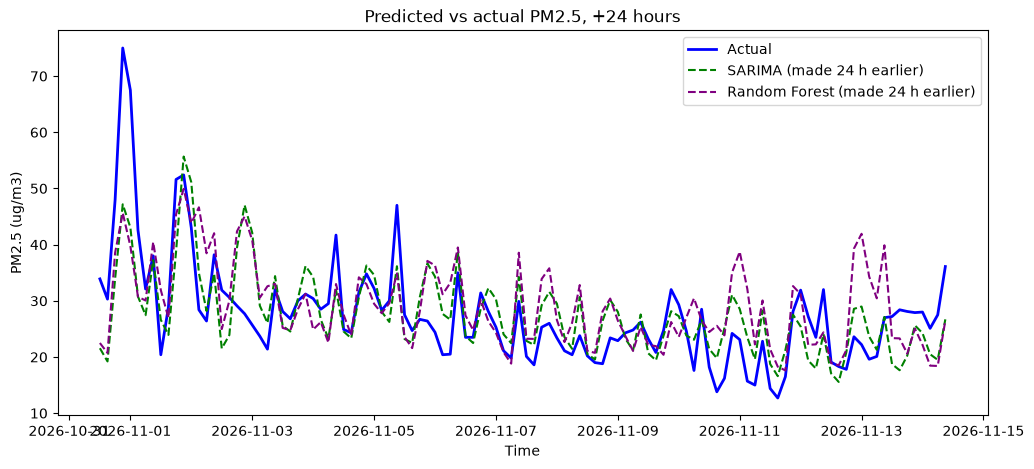

In [38]:
# machine learning predictions, with the time of the hour they predicted
ml_backtest = pd.DataFrame({
    "time": table["time"][index_24 + 24].values,
    "linear_24h": linear_24_guess,
    "random_forest_24h": forest_24_guess,
})

# SARIMA and naive predictions from Part 2
sarima_backtest = pd.DataFrame(backtest_list)

backtest = pd.merge(sarima_backtest, ml_backtest, on="time")
backtest = backtest.round(2)
backtest.to_csv("backtest_24h.csv", index=False)
print("Saved backtest_24h.csv with", len(backtest), "rows")

# last 14 days of the test period
last_part = backtest[-14 * 8:]      # one point every 3 hours = 8 points per day

plt.figure(figsize=(12, 5))
plt.plot(last_part["time"], last_part["real"], color="blue", linewidth=2, label="Actual")
plt.plot(last_part["time"], last_part["sarima_24h"], color="green", linestyle="--", label="SARIMA (made 24 h earlier)")
plt.plot(last_part["time"], last_part["random_forest_24h"], color="purple", linestyle="--", label="Random Forest (made 24 h earlier)")
plt.title("Predicted vs actual PM2.5, +24 hours")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (do the predictions follow the actual line? do they miss the big spikes? do they react late?)

## Step 4: Compare everything with SARIMA and the naive baseline

In [39]:
sarima_table = pd.read_csv("sarima_results.csv")

compare = pd.merge(sarima_table, ml_table, on="horizon_hours")
compare = compare.round(2)
print(compare)

compare.to_csv("model_comparison.csv", index=False)

   horizon_hours  SARIMA_RMSE  SARIMA_MAE  Naive_RMSE  Naive_MAE  \
0              1         1.76        1.09        6.49       4.71   
1              6         5.68        3.89        6.44       4.70   
2             24         6.67        4.73        6.46       4.74   
3             48         8.15        5.74        8.00       5.95   
4             72         9.01        6.42        9.19       6.84   

   LinearRegression_RMSE  LinearRegression_MAE  RandomForest_RMSE  \
0                   1.91                  1.18               1.78   
1                   5.79                  4.25               5.32   
2                   6.21                  4.78               6.31   
3                   7.52                  5.79               7.66   
4                   8.14                  6.32               8.32   

   RandomForest_MAE  GradientBoosting_RMSE  GradientBoosting_MAE  
0              1.11                   1.90                  1.23  
1              3.78                   5.38

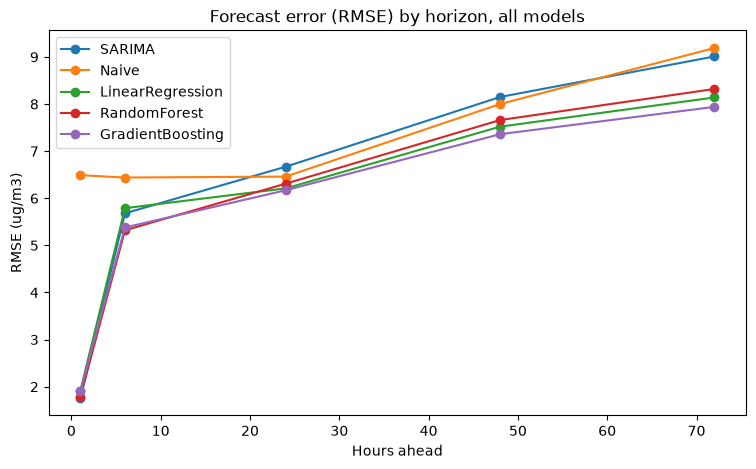

In [40]:
plt.figure(figsize=(9, 5))

for column in compare.columns:
    if column.endswith("_RMSE"):
        name = column.replace("_RMSE", "")
        plt.plot(compare["horizon_hours"], compare[column], marker="o", label=name)

plt.title("Forecast error (RMSE) by horizon, all models")
plt.xlabel("Hours ahead")
plt.ylabel("RMSE (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (which model has the lowest error at each horizon? does any model beat the naive baseline?
Does the error grow with the horizon? Remember each horizon uses only about 16 starting points.)

### Step 4b: Is the difference real? (Diebold-Mariano test)
One model can have a lower RMSE just by luck. This test asks: are two models' squared errors really different?
- **p-value below 0.05:** the difference is probably real.
- **p-value above 0.05:** we cannot say one is better.

Forecasts from nearby starting points are related, so the test includes a correction for that (Newey-West).

In [41]:
from scipy import stats

def dm_test(errors_a, errors_b, lag):
    # compare squared errors of two models. Negative stat means model A is better.
    d = np.array(errors_a) ** 2 - np.array(errors_b) ** 2
    n = len(d)
    mean_d = d.mean()

    # variance, with a correction for errors that are related to each other
    variance = np.mean((d - mean_d) ** 2)
    for k in range(1, lag + 1):
        weight = 1 - k / (lag + 1)
        covariance = np.mean((d[k:] - mean_d) * (d[:-k] - mean_d))
        variance = variance + 2 * weight * covariance

    if variance <= 0:
        return np.nan, np.nan

    stat = mean_d / np.sqrt(variance / n)
    p_value = 2 * (1 - stats.norm.cdf(abs(stat)))
    return stat, p_value


def verdict(name_a, name_b, stat, p_value):
    if np.isnan(p_value):
        return "could not test"
    if p_value >= 0.05:
        return "no clear difference"
    if stat < 0:
        return name_a + " is better"
    return name_b + " is better"


significance_rows = []

for h in horizons:
    lag = max(0, (h - 1) // origin_step)
    sarima_e = np.array(sarima_errors[h])
    naive_e = np.array(naive_errors[h])

    # SARIMA against the naive baseline
    stat, p_value = dm_test(sarima_e, naive_e, lag)
    significance_rows.append({"horizon_hours": h, "comparison": "SARIMA vs Naive",
                              "p_value": round(p_value, 3), "result": verdict("SARIMA", "Naive", stat, p_value)})

    # each machine learning model against SARIMA
    for name in ["LinearRegression", "RandomForest", "GradientBoosting"]:
        key = name + "_" + str(h)
        if key not in ml_errors:
            continue
        if len(ml_errors[key]) != len(sarima_e):
            print("Different number of starting points for", key, "- skipped")
            continue
        stat, p_value = dm_test(ml_errors[key], sarima_e, lag)
        significance_rows.append({"horizon_hours": h, "comparison": name + " vs SARIMA",
                                  "p_value": round(p_value, 3), "result": verdict(name, "SARIMA", stat, p_value)})

significance_table = pd.DataFrame(significance_rows)
print(significance_table.to_string())
significance_table.to_csv("significance_results.csv", index=False)

    horizon_hours                  comparison  p_value                      result
0               1             SARIMA vs Naive    0.000            SARIMA is better
1               1  LinearRegression vs SARIMA    0.000            SARIMA is better
2               1      RandomForest vs SARIMA    0.692         no clear difference
3               1  GradientBoosting vs SARIMA    0.001            SARIMA is better
4               6             SARIMA vs Naive    0.001            SARIMA is better
5               6  LinearRegression vs SARIMA    0.465         no clear difference
6               6      RandomForest vs SARIMA    0.011      RandomForest is better
7               6  GradientBoosting vs SARIMA    0.034  GradientBoosting is better
8              24             SARIMA vs Naive    0.506         no clear difference
9              24  LinearRegression vs SARIMA    0.025  LinearRegression is better
10             24      RandomForest vs SARIMA    0.103         no clear difference
11  

**Interpretation:** (at which horizons is SARIMA clearly better than the naive baseline? do the machine learning models beat SARIMA
or is the difference not clear? "no clear difference" is a valid, honest result.)

## Step 5: Which features matter? (+24 hours)

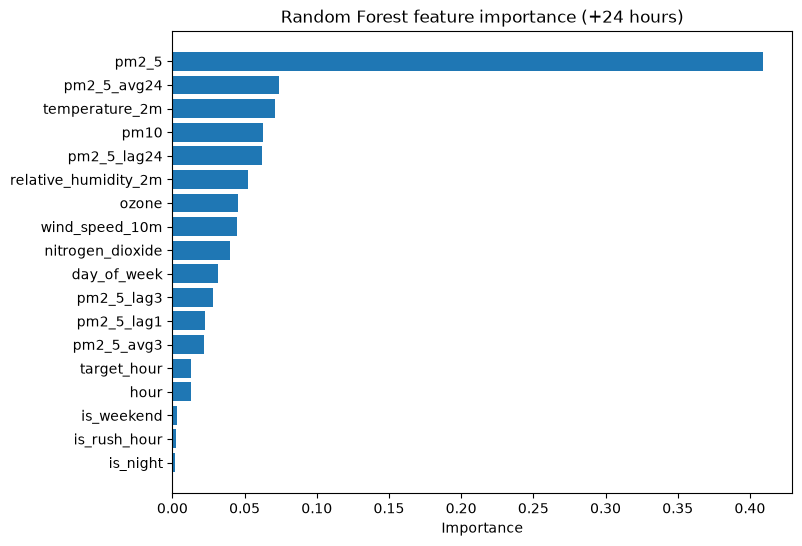

In [42]:
x_train, y_train, x_test, y_test = make_data(24, all_features)

forest_24 = RandomForestRegressor(n_estimators=200, random_state=42)
forest_24.fit(x_train, y_train)

importance = pd.Series(forest_24.feature_importances_, index=x_train.columns)
importance = importance.sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values)
plt.title("Random Forest feature importance (+24 hours)")
plt.xlabel("Importance")
plt.show()

**Interpretation:** (which 3 features matter most? are weather features important or is it mostly past PM2.5?)

In [43]:
# Linear Regression numbers (on scaled columns, so sizes can be compared)
mean = x_train.mean()
std = x_train.std().replace(0, 1)
linear_24 = LinearRegression()
linear_24.fit((x_train - mean) / std, y_train)

coefficients = pd.Series(linear_24.coef_, index=x_train.columns).sort_values()
print(coefficients.round(2))

temperature_2m         -1.58
relative_humidity_2m   -1.51
pm2_5_lag1             -0.77
ozone                  -0.74
pm2_5_lag3             -0.73
nitrogen_dioxide       -0.45
pm10                   -0.26
pm2_5_avg24            -0.23
is_weekend             -0.23
is_night                0.22
hour                    0.24
target_hour             0.24
is_rush_hour            0.31
wind_speed_10m          0.31
day_of_week             0.42
pm2_5_avg3              0.84
pm2_5_lag24             1.34
pm2_5                   7.67
dtype: float64


**Interpretation:** (positive number = PM2.5 goes up when this goes up; negative = goes down. Is wind negative?)

## Step 6: Sensitivity check (Random Forest, +24 hours)
Do the results change if we remove the weather columns, or train on a shorter window?

In [44]:
sensitivity_rows = []

# all features (normal)
x_train, y_train, x_test, y_test = make_data(24, all_features)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "All features", "RMSE": rmse, "MAE": mae})

# without weather columns
no_weather = []
for name in all_features:
    if name not in weather_features:
        no_weather.append(name)

x_train, y_train, x_test, y_test = make_data(24, no_weather)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "Without weather", "RMSE": rmse, "MAE": mae})

# shorter training window (only the later half of the training period)
x_train, y_train, x_test, y_test = make_data(24, all_features, first_train_row=test_start // 2)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "Shorter training window", "RMSE": rmse, "MAE": mae})

sensitivity_table = pd.DataFrame(sensitivity_rows).round(2)
print(sensitivity_table)
sensitivity_table.to_csv("sensitivity_results.csv", index=False)

                   version  RMSE   MAE
0             All features  6.31  4.63
1          Without weather  6.59  4.85
2  Shorter training window  6.38  4.79


**Interpretation:** (do the results change a lot? what does that say about how stable the model is?)

## Step 7 (optional): "High PM2.5 or not" in 24 hours
This turns the forecast into a yes/no question, so we can use a confusion matrix, precision, recall, F1 and ROC/AUC.
"High" means above the 75th percentile of the training hours (so both classes have enough examples).

In [45]:
high_limit = table["pm2_5"][:test_start].quantile(0.75)
print("High PM2.5 means above:", round(high_limit, 1))

table["high_in_24h"] = 0
table.loc[table["pm2_5"].shift(-24) > high_limit, "high_in_24h"] = 1

columns = all_features + ["target_hour"]
table["target_hour"] = table["hour"]       # +24 hours is the same hour of day

train_rows = list(range(0, test_start - 24))
test_rows = list(range(test_start - 1, len(table) - 24))     # every hour in the test period

x_train = table.loc[train_rows, columns]
y_train = table.loc[train_rows, "high_in_24h"]
x_test = table.loc[test_rows, columns]
y_test = table.loc[test_rows, "high_in_24h"]

classifier = RandomForestClassifier(n_estimators=200, random_state=42)
classifier.fit(x_train, y_train)

answer = classifier.predict(x_test)
chance = classifier.predict_proba(x_test)[:, 1]

print("Confusion matrix (rows = real, columns = predicted):")
print(confusion_matrix(y_test, answer))
print("Precision:", round(precision_score(y_test, answer, zero_division=0), 2))
print("Recall:", round(recall_score(y_test, answer, zero_division=0), 2))
print("F1 score:", round(f1_score(y_test, answer, zero_division=0), 2))

if len(set(y_test)) == 2:
    print("ROC AUC:", round(roc_auc_score(y_test, chance), 2))
else:
    print("ROC AUC needs both classes in the test period.")

High PM2.5 means above: 35.4


Confusion matrix (rows = real, columns = predicted):
[[3025   58]
 [ 281  115]]


Precision: 0.66
Recall: 0.29
F1 score: 0.4
ROC AUC: 0.89


**Interpretation:** (how many high hours did we catch? how many false alarms?)

### Step 7b (optional): improving the "high PM2.5" classifier
Four changes that usually help, each one explained:
1. **More past-value columns** (2, 6, 12, 48 and 168 hours ago, plus the 24-hour maximum, spread, and change).
2. **`class_weight="balanced"`** so the rarer class (high hours) counts more during training.
3. **A better decision threshold.** By default an hour is called "high" when the chance is above 0.5. A lower threshold catches more high hours (more recall) but gives more false alarms.
   The threshold is chosen on a validation slice taken from the END of the training period, never from the test period.
4. **A simple baseline** ("high now means high tomorrow") so we can see whether the model really adds anything.

In [46]:
from sklearn.metrics import accuracy_score, average_precision_score

# ---------- 1. more columns ----------
extra = table.copy()
past_pm = extra["pm2_5"]

extra["pm2_5_lag2"] = past_pm.shift(2)
extra["pm2_5_lag6"] = past_pm.shift(6)
extra["pm2_5_lag12"] = past_pm.shift(12)
extra["pm2_5_lag48"] = past_pm.shift(48)
extra["pm2_5_lag168"] = past_pm.shift(168)          # same hour, one week ago
extra["pm2_5_max24"] = past_pm.rolling(24).max()
extra["pm2_5_std24"] = past_pm.rolling(24).std()
extra["pm2_5_change24"] = past_pm - past_pm.shift(24)

new_columns = ["pm2_5_lag2", "pm2_5_lag6", "pm2_5_lag12", "pm2_5_lag48", "pm2_5_lag168",
               "pm2_5_max24", "pm2_5_std24", "pm2_5_change24"]
better_columns = all_features + new_columns + ["target_hour"]

# ---------- rows (the first 168 rows have no one-week-ago value) ----------
train_rows = list(range(168, test_start - 24))
test_rows = list(range(test_start - 1, len(extra) - 24))

x_train = extra.loc[train_rows, better_columns]
y_train = extra.loc[train_rows, "high_in_24h"]
x_test = extra.loc[test_rows, better_columns]
y_test = extra.loc[test_rows, "high_in_24h"]

# is the share of high hours very different in training and testing? (this alone can lower the scores)
print("Share of high hours in training:", round(y_train.mean() * 100, 1), "%")
print("Share of high hours in testing: ", round(y_test.mean() * 100, 1), "%")

# ---------- 3. choose the threshold on a validation slice (end of the training period) ----------
split_point = int(len(x_train) * 0.8)
fit_x = x_train[:split_point]
fit_y = y_train[:split_point]
val_x = x_train[split_point:]
val_y = y_train[split_point:]

# ---------- 2. balanced class weights ----------
check_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42)
check_model.fit(fit_x, fit_y)
val_chance = check_model.predict_proba(val_x)[:, 1]

best_threshold = 0.5
best_f1 = -1
for threshold in [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]:
    val_answer = (val_chance >= threshold).astype(int)
    score = f1_score(val_y, val_answer, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best threshold on the validation slice:", best_threshold)

# ---------- final model on all training rows, judged on the test period ----------
better_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42)
better_model.fit(x_train, y_train)
better_chance = better_model.predict_proba(x_test)[:, 1]
better_answer = (better_chance >= best_threshold).astype(int)

# ---------- the original model from Step 7 and the simple baseline ----------
original_answer = classifier.predict(table.loc[test_rows, all_features + ["target_hour"]])
baseline_answer = (extra.loc[test_rows, "pm2_5"] > high_limit).astype(int)     # high now = high tomorrow

def score_row(name, real, guess, chance=None):
    row = {
        "version": name,
        "accuracy": round(accuracy_score(real, guess), 2),
        "precision": round(precision_score(real, guess, zero_division=0), 2),
        "recall": round(recall_score(real, guess, zero_division=0), 2),
        "F1": round(f1_score(real, guess, zero_division=0), 2),
    }
    if chance is not None and len(set(real)) == 2:
        row["ROC_AUC"] = round(roc_auc_score(real, chance), 2)
        row["PR_AUC"] = round(average_precision_score(real, chance), 2)
    return row

compare_rows = [
    score_row("Baseline: high now = high tomorrow", y_test, baseline_answer),
    score_row("Step 7 model", y_test, original_answer),
    score_row("Improved model (7b)", y_test, better_answer, better_chance),
]

classifier_table = pd.DataFrame(compare_rows)
print(classifier_table.to_string())
classifier_table.to_csv("classifier_comparison.csv", index=False)

print("")
print("Confusion matrix of the improved model (rows = real, columns = predicted):")
print(confusion_matrix(y_test, better_answer))

Share of high hours in training: 24.9 %
Share of high hours in testing:  11.4 %


Best threshold on the validation slice: 0.45


                              version  accuracy  precision  recall    F1  ROC_AUC  PR_AUC
0  Baseline: high now = high tomorrow      0.90       0.57    0.54  0.56      NaN     NaN
1                        Step 7 model      0.90       0.66    0.29  0.40      NaN     NaN
2                 Improved model (7b)      0.89       0.53    0.55  0.54     0.89    0.56

Confusion matrix of the improved model (rows = real, columns = predicted):
[[2889  194]
 [ 177  219]]


**Interpretation:** (did recall go up? did precision drop when the threshold was lowered? that trade-off is normal.
Does the improved model beat the simple baseline? If not, say that 24-hour PM2.5 is hard to predict from this data. That is an honest result.
Also check the two "share of high hours" numbers: a big difference between training and testing explains part of a low score.)

## Step 8: Save the Random Forest (+24 hours) for the dashboard

In [47]:
x_train, y_train, x_test, y_test = make_data(24, all_features)

final_model = RandomForestRegressor(n_estimators=200, random_state=42)
final_model.fit(x_train, y_train)

saved = {"model": final_model, "features": list(x_train.columns)}

with open("model.pkl", "wb") as file:
    pickle.dump(saved, file)

print("Saved model.pkl")

Saved model.pkl


## Notes for the report
- ML models forecast each horizon directly (a separate model for +1, +6, +24, +48, +72 hours).
- Test starting points are the same as SARIMA's, so the comparison is fair.
- The "high PM2.5" label uses the 75th percentile of training hours, not a health standard.
- Next: Phase 7 (`app.py`) reads `model_comparison.csv` and `model.pkl`.

# Part 4: Checks against real-world data
Our data comes from a model (CAMS), not from sensors. These two checks test how far it can be trusted.
Both are optional: a cell skips itself with a message if its file is missing.

## Check A: compare with a real ground sensor
1. Get hourly PM2.5 readings for Karachi from a real monitor, for the same dates as your data. Options: the OpenAQ website (free account),
   or AirNow / the US Consulate monitor if one is listed for Karachi.
2. Save it as `ground_sensor.csv` in the project folder, with one column for the time and one for PM2.5 (ug/m3).
3. Set the three names below to match your file.

In [48]:
import os

# ----- change these to match your file -----
sensor_file = "ground_sensor.csv"
sensor_time_column = "time"
sensor_value_column = "pm2_5"
sensor_time_is_utc = True       # OpenAQ files use UTC. Use False if your times are already Karachi time.

In [49]:
if not os.path.exists(sensor_file):
    print("File not found:", sensor_file, "- skipping Check A.")
else:
    sensor = pd.read_csv(sensor_file)

    # make the times Karachi local time, rounded down to the hour
    if sensor_time_is_utc:
        sensor_time = pd.to_datetime(sensor[sensor_time_column], utc=True)
        sensor_time = sensor_time.dt.tz_convert("Asia/Karachi").dt.tz_localize(None)
    else:
        sensor_time = pd.to_datetime(sensor[sensor_time_column])

    sensor["time"] = sensor_time.dt.floor("h")
    sensor["sensor_pm2_5"] = sensor[sensor_value_column]

    # one value per hour
    sensor = sensor.groupby("time")["sensor_pm2_5"].mean().reset_index()

    # the model data (CAMS) for the same hours
    model_data = pd.read_csv("karachi_aq_history.csv")
    model_data["time"] = pd.to_datetime(model_data["time"])
    model_data = model_data[["time", "pm2_5"]]

    both = pd.merge(model_data, sensor, on="time")
    both = both.dropna()
    print("Hours in common:", len(both))

    if len(both) < 24:
        print("Fewer than 24 hours in common - check the dates and time zone of your file.")
    else:
        difference = both["pm2_5"] - both["sensor_pm2_5"]

        print("Correlation:", round(np.corrcoef(both["pm2_5"], both["sensor_pm2_5"])[0, 1], 2))
        print("Average difference (model minus sensor):", round(difference.mean(), 1), "ug/m3")
        print("RMSE:", round(np.sqrt(np.mean(difference ** 2)), 1), "ug/m3")
        print("MAE:", round(np.mean(np.abs(difference)), 1), "ug/m3")

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.scatter(both["sensor_pm2_5"], both["pm2_5"], s=5)
        top = max(both["sensor_pm2_5"].max(), both["pm2_5"].max())
        plt.plot([0, top], [0, top], color="red", linestyle="--", label="Perfect match")
        plt.title("Model vs ground sensor")
        plt.xlabel("Sensor PM2.5")
        plt.ylabel("Model PM2.5")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(both["time"], both["sensor_pm2_5"], label="Sensor")
        plt.plot(both["time"], both["pm2_5"], label="Model")
        plt.title("Over time")
        plt.xlabel("Time")
        plt.legend()

        plt.tight_layout()
        plt.show()

File not found: ground_sensor.csv - skipping Check A.


**Interpretation:** (high correlation but a big average difference means the model follows the ups and downs but is too high or too low.
Say clearly how much the CAMS data can be trusted for Karachi.)

## Check B: compare with Open-Meteo's own 24-hour forecast
`collector.py` and `collect_once.py` save Open-Meteo's own forecast for 24 hours ahead into `forecast_log.csv` every hour.
After some days, we can compare, for the same hours: Open-Meteo's forecast, our Random Forest, and the naive baseline.
This check needs several days of logging, so start the collector early.

In [50]:
import pickle

log_file = "forecast_log.csv"

if not os.path.exists(log_file):
    print("File not found:", log_file, "- start collector.py (or collect_once.py) and come back after a few days.")
else:
    log = pd.read_csv(log_file)
    log["made_at"] = pd.to_datetime(log["made_at"])
    log["target_time"] = pd.to_datetime(log["target_time"])

    data = pd.read_csv("clean_data.csv")
    data["time"] = pd.to_datetime(data["time"])
    data["target_hour"] = data["hour"]

    with open("model.pkl", "rb") as file:
        saved = pickle.load(file)

    check_rows = []
    for index in range(len(log)):
        made_at = log["made_at"][index]
        target_time = log["target_time"][index]

        now_row = data[data["time"] == made_at]
        target_row = data[data["time"] == target_time]

        # only use hours where we know both the starting row and the real result
        if len(now_row) == 1 and len(target_row) == 1:
            real = target_row["pm2_5"].values[0]
            forest_guess = saved["model"].predict(now_row[saved["features"]])[0]
            naive_guess = now_row["pm2_5"].values[0]
            openmeteo_guess = log["openmeteo_pm2_5_forecast"][index]

            check_rows.append({"real": real, "openmeteo": openmeteo_guess,
                               "random_forest": forest_guess, "naive": naive_guess})

    check = pd.DataFrame(check_rows).dropna()
    print("Forecasts we can check:", len(check))

    if len(check) < 24:
        print("Fewer than 24 forecasts so far - collect for a few more days.")
    else:
        result_rows = []
        for name in ["openmeteo", "random_forest", "naive"]:
            errors = check["real"] - check[name]
            result_rows.append({"forecast": name,
                                "RMSE": round(np.sqrt(np.mean(errors ** 2)), 2),
                                "MAE": round(np.mean(np.abs(errors)), 2)})
        print(pd.DataFrame(result_rows))

File not found: forecast_log.csv - start collector.py (or collect_once.py) and come back after a few days.


**Interpretation:** (does our Random Forest come close to Open-Meteo's forecast? if it is worse, that is fine: their forecast comes from a much bigger model.
Note that the Random Forest was trained earlier, and the "real" values come from the same CAMS source.)

## Notes for the report (Part 4)
- Check A shows whether CAMS data matches a real monitor in Karachi. It is the biggest limitation of the project, so report the result honestly.
- Check B compares live 24-hour forecasts. It only has as many rows as you collected.

# Part 5: Improving the accuracy
Ideas that raise the scores in an honest way (no peeking at the test period).
Run Parts 1 to 3 first, because this part uses their results.

## 5A: Accuracy as health categories
"Accuracy" is easier to understand as: did the model predict the right health category (Good, Moderate, Unhealthy ...)?
We turn the +24 hour predictions we already made (`backtest_24h.csv`) into categories and count how often they match.
- **Exact:** the predicted category equals the real one.
- **Within one:** off by at most one category.
- **Within 10:** the number itself is within 10 ug/m3.

In [51]:
from sklearn.metrics import r2_score

# US EPA PM2.5 category limits (2024): Good, Moderate, Unhealthy for sensitive groups, Unhealthy, Very unhealthy, Hazardous
category_limits = [9.0, 35.4, 55.4, 125.4, 225.4]
category_names = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very unhealthy", "Hazardous"]

def category_number(value):
    number = 0
    for limit in category_limits:
        if value > limit:
            number = number + 1
    return number

backtest_cat = pd.read_csv("backtest_24h.csv")
real_cat = backtest_cat["real"].apply(category_number)

category_rows = []
for name in ["naive_24h", "linear_24h", "sarima_24h", "random_forest_24h"]:
    guess_cat = backtest_cat[name].apply(category_number)

    exact = (guess_cat == real_cat).mean() * 100
    within_one = ((guess_cat - real_cat).abs() <= 1).mean() * 100
    within_10 = ((backtest_cat[name] - backtest_cat["real"]).abs() <= 10).mean() * 100

    category_rows.append({
        "model": name.replace("_24h", ""),
        "exact_category_%": round(exact, 1),
        "within_one_category_%": round(within_one, 1),
        "within_10_ug_%": round(within_10, 1),
    })

category_table = pd.DataFrame(category_rows)
print(category_table.to_string())
category_table.to_csv("category_accuracy.csv", index=False)

# confusion matrix for Random Forest (rows = real category, columns = predicted category)
forest_cat = backtest_cat["random_forest_24h"].apply(category_number)
print("")
print("Random Forest category confusion matrix (0 = Good ... 5 = Hazardous):")
print(pd.crosstab(real_cat, forest_cat, rownames=["real"], colnames=["predicted"]))

           model  exact_category_%  within_one_category_%  within_10_ug_%
0          naive              90.2                   99.9            88.8
1         linear              90.8                   99.9            91.3
2         sarima              90.2                   99.8            87.5
3  random_forest              89.9                   99.9            89.3

Random Forest category confusion matrix (0 = Good ... 5 = Hazardous):


predicted    1   2
real              
0            1   0
1          989  30
2           76  39
3            1   8


**Interpretation:** (which model gets the category right most often? is "within one category" much higher than "exact"?
Most misses are usually one category off, which is a much smaller mistake than a wrong number suggests.)

## 5B: Better regression models
Three changes, tested at +6 and +24 hours:
- **A. Direct** (what Part 3 does): predict the PM2.5 value.
- **B. Predict the change:** predict how much PM2.5 will change from now, then add it to the current value. The model no longer has to learn the level, only the movement, which is usually easier.
- **C. Change + extra columns:** B plus more past-value columns (2, 6, 12, 48 and 168 hours ago, 24-hour maximum, spread and change).
- **D. Average:** the mean of SARIMA and C (only +24 h, because that is the horizon we saved SARIMA predictions for).

R2 is the share of the ups and downs the model explains (1.0 is perfect, 0 is no better than the average).

In [52]:
# extra past-value columns, added to the table so make_data() can use them
past_pm = table["pm2_5"]

table["pm2_5_lag2"] = past_pm.shift(2)
table["pm2_5_lag6"] = past_pm.shift(6)
table["pm2_5_lag12"] = past_pm.shift(12)
table["pm2_5_lag48"] = past_pm.shift(48)
table["pm2_5_lag168"] = past_pm.shift(168)
table["pm2_5_max24"] = past_pm.rolling(24).max()
table["pm2_5_std24"] = past_pm.rolling(24).std()
table["pm2_5_change24"] = past_pm - past_pm.shift(24)

new_columns = ["pm2_5_lag2", "pm2_5_lag6", "pm2_5_lag12", "pm2_5_lag48", "pm2_5_lag168",
               "pm2_5_max24", "pm2_5_std24", "pm2_5_change24"]
better_features = all_features + new_columns


def score_all(real, guess):
    errors = np.array(real) - np.array(guess)
    return {
        "RMSE": round(np.sqrt(np.mean(errors ** 2)), 2),
        "MAE": round(np.mean(np.abs(errors)), 2),
        "R2": round(r2_score(real, guess), 3),
    }


experiment_rows = []

for h in [6, 24]:
    # A. direct
    x_train, y_train, x_test, y_test = make_data(h, all_features)
    model_a = RandomForestRegressor(n_estimators=200, random_state=42)
    model_a.fit(x_train, y_train)
    row = {"horizon_hours": h, "version": "A. Direct"}
    row.update(score_all(y_test, model_a.predict(x_test)))
    experiment_rows.append(row)

    # B. predict the change from now
    change_train = y_train - x_train["pm2_5"]
    model_b = RandomForestRegressor(n_estimators=200, random_state=42)
    model_b.fit(x_train, change_train)
    guess_b = np.array(x_test["pm2_5"]) + model_b.predict(x_test)
    row = {"horizon_hours": h, "version": "B. Predict the change"}
    row.update(score_all(y_test, guess_b))
    experiment_rows.append(row)

    # C. change + extra columns (the first 168 rows have no one-week-ago value, so we start later)
    x_train2, y_train2, x_test2, y_test2 = make_data(h, better_features, first_train_row=168)
    change_train2 = y_train2 - x_train2["pm2_5"]
    model_c = RandomForestRegressor(n_estimators=200, random_state=42)
    model_c.fit(x_train2, change_train2)
    guess_c = np.array(x_test2["pm2_5"]) + model_c.predict(x_test2)
    row = {"horizon_hours": h, "version": "C. Change + extra columns"}
    row.update(score_all(y_test2, guess_c))
    experiment_rows.append(row)

    # D. average of SARIMA and C (only at +24 hours, where we saved the SARIMA predictions)
    if h == 24 and len(backtest_cat) == len(guess_c):
        guess_d = (np.array(backtest_cat["sarima_24h"]) + guess_c) / 2
        row = {"horizon_hours": h, "version": "D. Average of SARIMA and C"}
        row.update(score_all(y_test2, guess_d))
        experiment_rows.append(row)

    print("Done horizon", h)

experiment_table = pd.DataFrame(experiment_rows)
print(experiment_table.to_string())
experiment_table.to_csv("improvement_experiments.csv", index=False)

Done horizon 6


Done horizon 24
   horizon_hours                     version  RMSE   MAE     R2
0              6                   A. Direct  5.32  3.78  0.638
1              6       B. Predict the change  5.42  3.84  0.624
2              6   C. Change + extra columns  5.37  3.79  0.630
3             24                   A. Direct  6.31  4.63  0.490
4             24       B. Predict the change  6.29  4.67  0.494
5             24   C. Change + extra columns  6.20  4.66  0.509
6             24  D. Average of SARIMA and C  6.12  4.43  0.520


**Interpretation:** (which version has the lowest RMSE and the highest R2 at each horizon? does predicting the change help?
Do the extra columns help, or not? Report the result either way.)

## 5C: "High PM2.5 or not" using the regression forecast
The classifier in Step 7b ranks hours well (good ROC AUC) but its yes/no cut-off is hard to set, and the share of high hours changes between training and testing.
Here we use the number forecast instead: predict PM2.5 for tomorrow with the "predict the change" model, and call the hour **high** when the forecast is above a cut-off.
The cut-off is chosen on a validation slice taken from the END of the training period (never the test period) to give the best F1 score.

In [53]:
# ---------- rows ----------
now_pm = extra["pm2_5"]
future_pm = extra["pm2_5"].shift(-24)

train_rows2 = list(range(168, test_start - 24))
test_rows2 = list(range(test_start - 1, len(extra) - 24))

x_all_train = extra.loc[train_rows2, better_columns]
change_all_train = (future_pm - now_pm).loc[train_rows2]
high_all_train = extra.loc[train_rows2, "high_in_24h"]

x_final_test = extra.loc[test_rows2, better_columns]
high_final_test = extra.loc[test_rows2, "high_in_24h"]

# ---------- choose the cut-off on a validation slice (end of the training period) ----------
split_point = int(len(x_all_train) * 0.8)
fit_x = x_all_train[:split_point]
fit_change = change_all_train[:split_point]
val_x = x_all_train[split_point:]
val_high = high_all_train[split_point:]

check_regressor = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
check_regressor.fit(fit_x, fit_change)
val_forecast = np.array(val_x["pm2_5"]) + check_regressor.predict(val_x)

best_cutoff = high_limit
best_f1 = -1
for cutoff in np.arange(high_limit - 10, high_limit + 5.1, 1.0):
    val_answer = (val_forecast >= cutoff).astype(int)
    score = f1_score(val_high, val_answer, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_cutoff = cutoff

print("High means above:", round(high_limit, 1))
print("Best cut-off on the validation slice:", round(best_cutoff, 1))

# ---------- final model on all training rows, judged on the test period ----------
final_regressor = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
final_regressor.fit(x_all_train, change_all_train)
test_forecast = np.array(x_final_test["pm2_5"]) + final_regressor.predict(x_final_test)
forecast_answer = (test_forecast >= best_cutoff).astype(int)

# ---------- compare with the earlier versions ----------
new_row = score_row("5C: classify from the regression forecast", high_final_test, forecast_answer, test_forecast)
final_table = pd.concat([classifier_table, pd.DataFrame([new_row])], ignore_index=True)
print(final_table.to_string())
final_table.to_csv("classifier_comparison.csv", index=False)

print("")
print("Confusion matrix of 5C (rows = real, columns = predicted):")
print(confusion_matrix(high_final_test, forecast_answer))

High means above: 35.4
Best cut-off on the validation slice: 31.4


                                     version  accuracy  precision  recall    F1  ROC_AUC  PR_AUC
0         Baseline: high now = high tomorrow      0.90       0.57    0.54  0.56      NaN     NaN
1                               Step 7 model      0.90       0.66    0.29  0.40      NaN     NaN
2                        Improved model (7b)      0.89       0.53    0.55  0.54     0.89    0.56
3  5C: classify from the regression forecast      0.87       0.45    0.59  0.51     0.88    0.54

Confusion matrix of 5C (rows = real, columns = predicted):
[[2800  283]
 [ 162  234]]


**Interpretation:** (compare the F1 and recall columns, not accuracy: if only about 20% of hours are high, always answering "not high" already gives about 80% accuracy.
Does 5C beat the baseline? If a health warning is the goal, missing a high hour is worse than a false alarm, so a higher recall can be the better choice. Say which you chose and why.)

## 5D: Average several models (+24 hours)
Models with different strengths make different mistakes, so their average is often better than any one of them.
This uses the +24 hour predictions already saved in `backtest_24h.csv`, so nothing is retrained.

In [54]:
backtest_avg = pd.read_csv("backtest_24h.csv")

combinations = {
    "SARIMA + Linear": ["sarima_24h", "linear_24h"],
    "Linear + Random Forest": ["linear_24h", "random_forest_24h"],
    "SARIMA + Linear + Random Forest": ["sarima_24h", "linear_24h", "random_forest_24h"],
}

real_values = backtest_avg["real"]
real_category = real_values.apply(category_number)

ensemble_rows = []

# each model alone
for name in ["naive_24h", "sarima_24h", "linear_24h", "random_forest_24h"]:
    row = {"model": name.replace("_24h", "")}
    row.update(score_all(real_values, backtest_avg[name]))
    guess_category = backtest_avg[name].apply(category_number)
    row["exact_category_%"] = round((guess_category == real_category).mean() * 100, 1)
    ensemble_rows.append(row)

# averages of two or three models
for name, columns in combinations.items():
    average_guess = backtest_avg[columns].mean(axis=1)
    row = {"model": "AVERAGE: " + name}
    row.update(score_all(real_values, average_guess))
    guess_category = average_guess.apply(category_number)
    row["exact_category_%"] = round((guess_category == real_category).mean() * 100, 1)
    ensemble_rows.append(row)

ensemble_table = pd.DataFrame(ensemble_rows)
print(ensemble_table.to_string())
ensemble_table.to_csv("ensemble_results.csv", index=False)

# for context: how often would "always the most common category" be right?
most_common_share = real_category.value_counts().max() / len(real_category) * 100
print("")
print("Always guessing the most common category would be right", round(most_common_share, 1), "% of the time.")

                                      model  RMSE   MAE     R2  exact_category_%
0                                     naive  6.46  4.74  0.465              90.2
1                                    sarima  6.67  4.73  0.431              90.2
2                                    linear  6.21  4.78  0.507              90.8
3                             random_forest  6.31  4.63  0.490              89.9
4                  AVERAGE: SARIMA + Linear  6.18  4.48  0.512              91.0
5           AVERAGE: Linear + Random Forest  6.13  4.62  0.520              90.6
6  AVERAGE: SARIMA + Linear + Random Forest  6.08  4.44  0.527              90.9



Always guessing the most common category would be right 89.1 % of the time.


**Interpretation:** (does an average beat every single model on RMSE and R2? compare the exact-category score with the "always the most common category" line above:
if they are close, the category accuracy is mostly coming from one very common category and should be reported with that caveat.)

## 5E: Do we need more data? (learning curve, +24 hours)
We train on the most recent 25%, 50%, 75% and 100% of the training period and test every version on the same test hours.
- **Error still falling at 100%:** more data should help. Increase `history_days` in `backfill.py`.
- **Error flat:** more data of the same kind won't help. The models need new inputs, such as tomorrow's weather forecast.

   share_of_training_data  hours_used  Linear_RMSE  RandomForest_RMSE
0                    0.25        3496         6.41               7.00
1                    0.50        6991         6.18               6.41
2                    0.75       10486         6.13               6.19
3                    1.00       13981         6.21               6.31


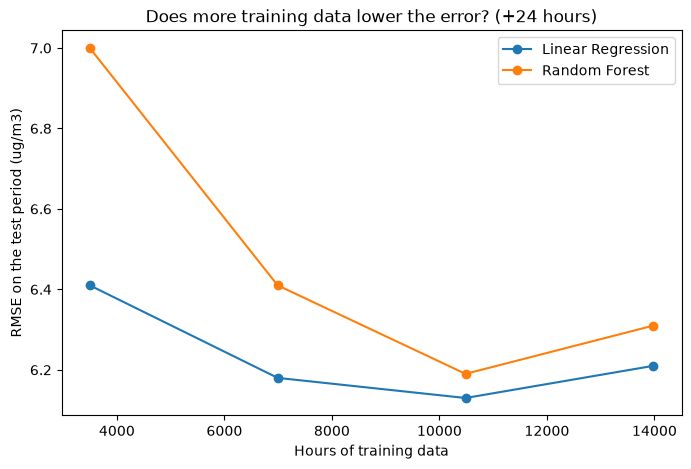

In [55]:
fractions = [0.25, 0.5, 0.75, 1.0]
curve_rows = []

for fraction in fractions:
    # use the most recent part of the training period (it ends right before the test period)
    first_row = int((test_start - 24) * (1 - fraction))
    x_train, y_train, x_test, y_test = make_data(24, all_features, first_train_row=first_row)

    # Linear Regression (columns scaled)
    mean = x_train.mean()
    std = x_train.std().replace(0, 1)
    linear_model = LinearRegression()
    linear_model.fit((x_train - mean) / std, y_train)
    linear_guess = linear_model.predict((x_test - mean) / std)
    linear_rmse, linear_mae = get_errors(y_test, linear_guess)

    # Random Forest
    forest_model = RandomForestRegressor(n_estimators=200, random_state=42)
    forest_model.fit(x_train, y_train)
    forest_guess = forest_model.predict(x_test)
    forest_rmse, forest_mae = get_errors(y_test, forest_guess)

    curve_rows.append({
        "share_of_training_data": fraction,
        "hours_used": len(x_train),
        "Linear_RMSE": round(linear_rmse, 2),
        "RandomForest_RMSE": round(forest_rmse, 2),
    })

curve_table = pd.DataFrame(curve_rows)
print(curve_table.to_string())
curve_table.to_csv("learning_curve.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(curve_table["hours_used"], curve_table["Linear_RMSE"], marker="o", label="Linear Regression")
plt.plot(curve_table["hours_used"], curve_table["RandomForest_RMSE"], marker="o", label="Random Forest")
plt.title("Does more training data lower the error? (+24 hours)")
plt.xlabel("Hours of training data")
plt.ylabel("RMSE on the test period (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (does the error keep dropping as the hours grow, or does it flatten? a flat curve means the limit is the inputs, not the amount of data.
Note that one year of data has only one example of each season, so also say that seasonal patterns cannot be learned from it.)

## What else can raise the scores
- **Report the short horizons first.** +1 and +6 hours are far easier than +24 or +72. Say clearly which horizon each number is for.
- **More history.** A year or more of data (`history_days` in `backfill.py`) lets the models learn seasons.
- **Tune with time-aware validation.** Try a few Random Forest settings (`n_estimators`, `min_samples_leaf`, `max_depth`) and pick by `TimeSeriesSplit`, never by the test period.
- **Gradient Boosting** after it is taught in class.
- **Forecast a smoother target,** such as the average of the next 6 hours, which is less noisy than a single hour.

## What not to do
- Do not shuffle the data randomly before splitting.
- Do not choose settings or thresholds by looking at the test period.
- Do not use values from after the starting point as inputs (leakage). The scores would look great but would be fake.